# PathVEK · Auditoría de navegabilidad de un ERP mediante grafos
**Estructuras de Datos y Algoritmos II · Proyecto del Primer Bimestre · 2026-B**
Escuela Politécnica Nacional · Docente: Lorena Recalde, Ph.D.

| Sección | Contenido |
|---|---|
| 0 | Portada, roles y costo |
| 1 | Problema del cliente |
| 2 | Modelado como grafo |
| 3 | Representación en Python y visualización |
| 4 | BFS |
| 5 | DFS |
| 6 | Casos de prueba |
| 7 | Comparación BFS vs DFS |
| 8 | Experimento estructural |
| 9 | AI-Audit |
| 10–14 | Recomendaciones, conclusiones, declaración de IA, referencias y contribuciones |

> Cuaderno reproducible: **Kernel → Restart Kernel and Run All Cells** ejecuta todo en orden.

---
## 0. Portada

| Campo | Detalle |
|---|---|
| **Startup** | PathVEK |
| **Cliente / sistema** | Empresa comercial que utiliza un ERP hipotético |
| **Servicio** | Auditoría de navegabilidad de un Sistema de Información |

### Integrantes y roles
| Integrante | Rol | Responsabilidades en este proyecto |
|---|---|---|
| Grefa Huatatoca Karen Mishelle | Product & SI Analyst | Problema del cliente, modelado y visualización del grafo, DFS, pruebas y comparación BFS vs DFS |
| Guachagmira Anrango Erick Said | Algorithm Engineer | Representación en Python y BFS |
| Guzman Pillajo Vianca Alejandra | QA & Insights Engineer | Experimento estructural y AI-Audit |

Los roles son responsabilidades principales, no exclusivas: los tres integrantes pueden explicar todo el proyecto.

### Costo de la consultoría
Estimación en horas por integrante a una tarifa de USD 10 por hora (valores de referencia del equipo).

In [1]:
tarifa_por_hora = 10  # USD por hora
horas = {
    "Karen (problema, grafo, DFS, pruebas, comparación)": 25,
    "Erick (representación y BFS)": 20,
    "Vianca (experimento y AI-Audit)": 20,
}
costo_fijo = 0  # herramientas o licencias

total = costo_fijo
for nombre, h in horas.items():
    total += h * tarifa_por_hora
    print(f"{nombre:52s} {h:3d} h   USD {h * tarifa_por_hora:7.2f}")
print(f"{'TOTAL DE LA CONSULTORÍA':52s}         USD {total:7.2f}")

Karen (problema, grafo, DFS, pruebas, comparación)    25 h   USD  250.00
Erick (representación y BFS)                          20 h   USD  200.00
Vianca (experimento y AI-Audit)                       20 h   USD  200.00
TOTAL DE LA CONSULTORÍA                                      USD  650.00


---
## 1. Problema del cliente

### Contexto
Una empresa comercial, que compra y vende productos, utiliza un sistema de planificación de recursos empresariales (ERP)
para gestionar ventas, compras, inventario, bodega, contabilidad y reportes. El sistema está organizado en pantallas
conectadas por opciones de navegación y lo usan personas con responsabilidades distintas.

### Problema
> **La empresa no sabe si la estructura de navegación de su ERP permite a los usuarios llegar a las pantallas que
> necesitan, con cuántos pasos lo hacen y desde qué pantallas quedan sin posibilidad de regresar.**
> No existe un análisis que muestre qué rutas hay entre pantallas, cuál es la más corta, qué pantallas se alcanzan desde
> un punto de partida y cómo cambia la navegación al agregar o quitar una conexión.

### Usuarios y necesidades
| Usuario | Qué necesita al navegar |
|---|---|
| **Vendedor** | Llegar rápido a clientes, pedidos y facturación. |
| **Contador** | Llegar a contabilidad, pagos y reportes financieros. |
| **Gerente** | Supervisar las operaciones y consultar reportes de todas las áreas. |

### Objetivo
Auditar la navegabilidad del ERP modelando su estructura como un grafo y analizándola con BFS y DFS, para entregar al
cliente evidencia sobre rutas, alcanzabilidad y el efecto de modificar una conexión.

### Consultas del cliente
| ID | Consulta | Algoritmo |
|---|---|---|
| **C1** | ¿Cuál es la ruta con menos pasos desde **Menú Principal** hasta **Reportes financieros**? | BFS |
| **C2** | ¿Qué pantallas se pueden alcanzar desde **Facturación** y cuáles no? | DFS |
| **C3** | Si se agrega una conexión de **Contabilidad** a **Menú Principal**, ¿cambia lo que se puede alcanzar desde Facturación? | BFS y DFS, antes y después |

### Solución propuesta
Un prototipo analítico en Python que representa la navegación como un **grafo dirigido y no ponderado** (cada vértice es
una pantalla y cada arista un clic entre pantallas) y lo analiza con **BFS** y **DFS** implementados con lógica propia.

### Alcance y límites
- Se analiza **solo la estructura de navegación** del modelo: qué pantalla conecta con cuál.
- El ERP es **hipotético**: lo diseñó el equipo para este proyecto y no corresponde a un producto comercial real.
- Las conexiones son **navegación entre pantallas**, no procesos internos (que una venta descuente inventario es un
  proceso; que el usuario pase de *Pedidos de venta* a *Existencias* es navegación).
- Los usuarios **no** son vértices: son los perfiles desde los cuales se plantean las consultas.
- Los resultados **no** demuestran el funcionamiento interno, el rendimiento ni la seguridad de un ERP real.
- Fuera de alcance: aplicación web o móvil, base de datos, API, autenticación real y rutas ponderadas.

---
## 2. Modelado como grafo

### 2.1 Definiciones
| Elemento | Definición en este proyecto |
|---|---|
| **Grafo** | Conjunto de pantallas (vértices) y conexiones directas entre ellas (aristas). |
| **Vértice** | Una pantalla del ERP a la que el usuario puede llegar. |
| **Arista** | Una transición directa (un clic) de una pantalla a otra; cuenta como **un paso**. |
| **Grafo dirigido** | Cada arista tiene sentido: `A → B` indica que desde A se llega a B, no que desde B se pueda volver a A. |
| **No ponderado** | Todas las aristas valen lo mismo; la ruta más corta es la que usa menos aristas. |
| **Punto de entrada** | `Menú Principal`, al que se llega desde `Login`. |

### 2.2 Decisiones y justificación
| Decisión | Justificación |
|---|---|
| **Grafo dirigido** | En navegación, poder ir de A a B no garantiza poder volver. Con flechas se audita qué pantallas quedan sin retorno y qué se alcanza desde cada punto. En un grafo no dirigido todo sería alcanzable desde todo. |
| **No ponderado** | El cliente mide la facilidad de navegación en número de pasos, no en tiempo ni costo. |
| **Vértices = pantallas** | Es la unidad que el usuario ve y a la que quiere llegar; da la granularidad justa para analizar rutas. |
| **Aristas = clics directos** | Cada arista es un paso de navegación verificable. |
| **Ida y vuelta solo en acceso y menú** | `Login` y las pantallas de entrada de cada módulo tienen opción de volver al `Menú Principal`; dentro de un flujo (por ejemplo Facturación → Contabilidad) se avanza en un solo sentido. |
| **Flujo financiero sin retorno al menú** | Decisión de diseño del ERP hipotético: permite auditar pantallas sin salida hacia el resto del sistema. El experimento de la sección 8 evalúa agregar esa conexión. |

### 2.3 Vértices (20)
| # | Pantalla (vértice) | Área | Qué representa |
|---|---|---|---|
| 1 | **Login** | Acceso y administración | Pantalla de ingreso al sistema; punto de partida de todo usuario. |
| 2 | **Recuperar contraseña** | Acceso y administración | Restablece la clave cuando el usuario no puede ingresar. |
| 3 | **Menú Principal** | Acceso y administración | Pantalla central con acceso a cada módulo; punto de entrada principal. |
| 4 | **Usuarios** | Acceso y administración | Administración de las cuentas de usuario. |
| 5 | **Permisos de usuarios** | Acceso y administración | Asignación de permisos a cada usuario. |
| 6 | **Clientes** | Ventas | Consulta y registro de los clientes de la empresa. |
| 7 | **Pedidos de venta** | Ventas | Registro de las ventas solicitadas por los clientes. |
| 8 | **Facturación** | Ventas | Emisión de facturas; destino habitual del vendedor. |
| 9 | **Proveedores** | Compras | Consulta y registro de los proveedores. |
| 10 | **Órdenes de compra** | Compras | Solicitud de mercadería a un proveedor. |
| 11 | **Recepción de mercadería** | Compras | Registro de la mercadería que llega a la empresa. |
| 12 | **Existencias** | Inventario | Consulta del stock disponible de cada producto. |
| 13 | **Movimiento de inventario** | Inventario | Historial de entradas y salidas de mercadería. |
| 14 | **Bodega** | Inventario | Gestión de los lugares donde se almacena la mercadería. |
| 15 | **Contabilidad** | Finanzas | Registro contable; concentra información financiera de otras áreas. |
| 16 | **Cuentas por cobrar** | Finanzas | Valores que los clientes deben a la empresa. |
| 17 | **Cuentas por pagar** | Finanzas | Valores que la empresa debe a sus proveedores. |
| 18 | **Pagos** | Finanzas | Registro de pagos recibidos y realizados. |
| 19 | **Reportes comerciales** | Reportes | Informes de ventas e inventario. |
| 20 | **Reportes financieros** | Reportes | Informes financieros; destino del contador y del gerente. |

### 2.4 Aristas (37 aristas dirigidas)
Hay 9 conexiones de ida y vuelta (2 aristas cada una) y 19 de un solo sentido.

| # | Conexión | Sentido | Qué representa |
|---|---|---|---|
| 1 | Login ⇄ Recuperar contraseña | ida y vuelta (2 aristas) | Si olvida su clave, el usuario la recupera y regresa al login. |
| 2 | Login ⇄ Menú Principal | ida y vuelta (2 aristas) | Tras autenticarse entra al menú; desde el menú puede cerrar sesión. |
| 3 | Menú Principal ⇄ Clientes | ida y vuelta (2 aristas) | Entrada al módulo de clientes, con opción de volver al menú. |
| 4 | Menú Principal ⇄ Usuarios | ida y vuelta (2 aristas) | Entrada a la administración de usuarios, con opción de volver. |
| 5 | Menú Principal ⇄ Pedidos de venta | ida y vuelta (2 aristas) | Entrada directa a los pedidos, con opción de volver. |
| 6 | Menú Principal ⇄ Proveedores | ida y vuelta (2 aristas) | Entrada al módulo de compras, con opción de volver. |
| 7 | Menú Principal ⇄ Existencias | ida y vuelta (2 aristas) | Entrada a la consulta de stock, con opción de volver. |
| 8 | Menú Principal ⇄ Bodega | ida y vuelta (2 aristas) | Entrada a la gestión de bodegas, con opción de volver. |
| 9 | Usuarios ⇄ Permisos de usuarios | ida y vuelta (2 aristas) | Desde un usuario se ajustan sus permisos y se regresa. |
| 10 | Menú Principal → Contabilidad | un sentido (1 arista) | Entrada al módulo financiero; este módulo no tiene opción de volver al menú. |
| 11 | Clientes → Pedidos de venta | un sentido (1 arista) | Desde un cliente se crea o consulta su pedido. |
| 12 | Pedidos de venta → Existencias | un sentido (1 arista) | Al registrar un pedido se verifica el stock disponible. |
| 13 | Existencias → Facturación | un sentido (1 arista) | Desde el stock se factura la mercadería vendida. |
| 14 | Existencias → Movimiento de inventario | un sentido (1 arista) | Se consulta el historial de entradas y salidas del producto. |
| 15 | Facturación → Contabilidad | un sentido (1 arista) | La factura emitida pasa al registro contable. |
| 16 | Facturación → Cuentas por cobrar | un sentido (1 arista) | La factura genera la cuenta por cobrar del cliente. |
| 17 | Proveedores → Órdenes de compra | un sentido (1 arista) | Desde un proveedor se genera su orden de compra. |
| 18 | Órdenes de compra → Recepción de mercadería | un sentido (1 arista) | La orden aprobada lleva a registrar la recepción. |
| 19 | Recepción de mercadería → Existencias | un sentido (1 arista) | Lo recibido se refleja en el stock. |
| 20 | Recepción de mercadería → Bodega | un sentido (1 arista) | Se indica en qué bodega ingresa la mercadería. |
| 21 | Recepción de mercadería → Movimiento de inventario | un sentido (1 arista) | La recepción queda registrada como entrada de inventario. |
| 22 | Movimiento de inventario → Reportes comerciales | un sentido (1 arista) | Los movimientos alimentan los reportes de inventario y ventas. |
| 23 | Contabilidad → Reportes comerciales | un sentido (1 arista) | Se consultan reportes comerciales desde contabilidad. |
| 24 | Contabilidad → Reportes financieros | un sentido (1 arista) | Los datos contables se presentan en el reporte financiero. |
| 25 | Contabilidad → Pagos | un sentido (1 arista) | Se registran o consultan los pagos. |
| 26 | Reportes comerciales → Reportes financieros | un sentido (1 arista) | Se cruza la información comercial con la financiera. |
| 27 | Cuentas por cobrar → Pagos | un sentido (1 arista) | Un pago se aplica a una cuenta por cobrar. |
| 28 | Pagos → Cuentas por pagar | un sentido (1 arista) | Se revisan las cuentas pendientes de pago. |

### 2.5 Cumplimiento de los requisitos del proyecto
| Requisito | Cómo se cumple |
|---|---|
| 15–25 vértices | 20 pantallas. |
| 20–40 aristas | 37 aristas dirigidas. |
| No ponderado | Cada arista equivale a un paso. |
| Dirigido o no dirigido, justificado | Dirigido; justificación en 2.2. |
| Al menos un ciclo | Las conexiones de ida y vuelta forman ciclos, por ejemplo `Login ⇄ Recuperar contraseña` y `Menú Principal ⇄ Clientes`. |
| Par origen–destino con 2 o más rutas | `Menú Principal → Facturación`: directa por `Existencias` (2 aristas) o por `Pedidos de venta` y `Existencias` (3 aristas). |
| Pantallas no alcanzables desde algún origen | Desde `Facturación` no se llega a `Menú Principal` ni a otras 12 pantallas (se verifica con DFS en las secciones 5 y 6). |
| Cambio estructural con sentido | Agregar `Contabilidad → Menú Principal` (botón de volver del módulo financiero). |

---
## 3. Representación en Python

El grafo es un **diccionario de listas de adyacencia**: cada clave es una pantalla y su lista contiene las pantallas a las
que se llega con un clic.

In [2]:
grafo = {
    # Acceso y administración
    "Login":                    ["Recuperar contraseña", "Menú Principal"],
    "Recuperar contraseña":     ["Login"],
    "Menú Principal":           ["Login", "Clientes", "Usuarios", "Pedidos de venta", "Proveedores", "Existencias", "Bodega", "Contabilidad"],
    "Usuarios":                 ["Menú Principal", "Permisos de usuarios"],
    "Permisos de usuarios":     ["Usuarios"],
    # Ventas
    "Clientes":                 ["Menú Principal", "Pedidos de venta"],
    "Pedidos de venta":         ["Menú Principal", "Existencias"],
    "Facturación":              ["Contabilidad", "Cuentas por cobrar"],
    # Compras
    "Proveedores":              ["Menú Principal", "Órdenes de compra"],
    "Órdenes de compra":        ["Recepción de mercadería"],
    "Recepción de mercadería":  ["Existencias", "Bodega", "Movimiento de inventario"],
    # Inventario
    "Existencias":              ["Menú Principal", "Facturación", "Movimiento de inventario"],
    "Movimiento de inventario": ["Reportes comerciales"],
    "Bodega":                   ["Menú Principal"],
    # Finanzas
    "Contabilidad":             ["Reportes comerciales", "Reportes financieros", "Pagos"],
    "Cuentas por cobrar":       ["Pagos"],
    "Cuentas por pagar":        [],
    "Pagos":                    ["Cuentas por pagar"],
    # Reportes
    "Reportes comerciales":     ["Reportes financieros"],
    "Reportes financieros":     [],
}

In [3]:
vertices = set(grafo)
aristas = [(u, v) for u, vecinos in grafo.items() for v in vecinos]

print("Vértices:", len(vertices), "(requisito: 15 a 25)")
print("Aristas :", len(aristas), "(requisito: 20 a 40)")
print("Destinos no definidos como vértice:", {v for _, v in aristas if v not in vertices} or "ninguno")
print("Aristas repetidas:", len(aristas) - len(set(aristas)))
print("Pantallas sin aristas de salida:", [u for u in grafo if not grafo[u]] or "ninguna")

assert 15 <= len(vertices) <= 25
assert 20 <= len(aristas) <= 40
assert all(v in vertices for _, v in aristas)
assert len(aristas) == len(set(aristas))
print("\nModelo consistente.")

Vértices: 20 (requisito: 15 a 25)
Aristas : 37 (requisito: 20 a 40)
Destinos no definidos como vértice: ninguno
Aristas repetidas: 0
Pantallas sin aristas de salida: ['Cuentas por pagar', 'Reportes financieros']

Modelo consistente.


### Visualización del grafo
El dibujo usa **NetworkX y Matplotlib solo para visualizar**; no ejecutan ningún recorrido. Los colores indican el área de
cada pantalla. La celda siguiente exporta el grafo a **Gephi** para una visualización interactiva.

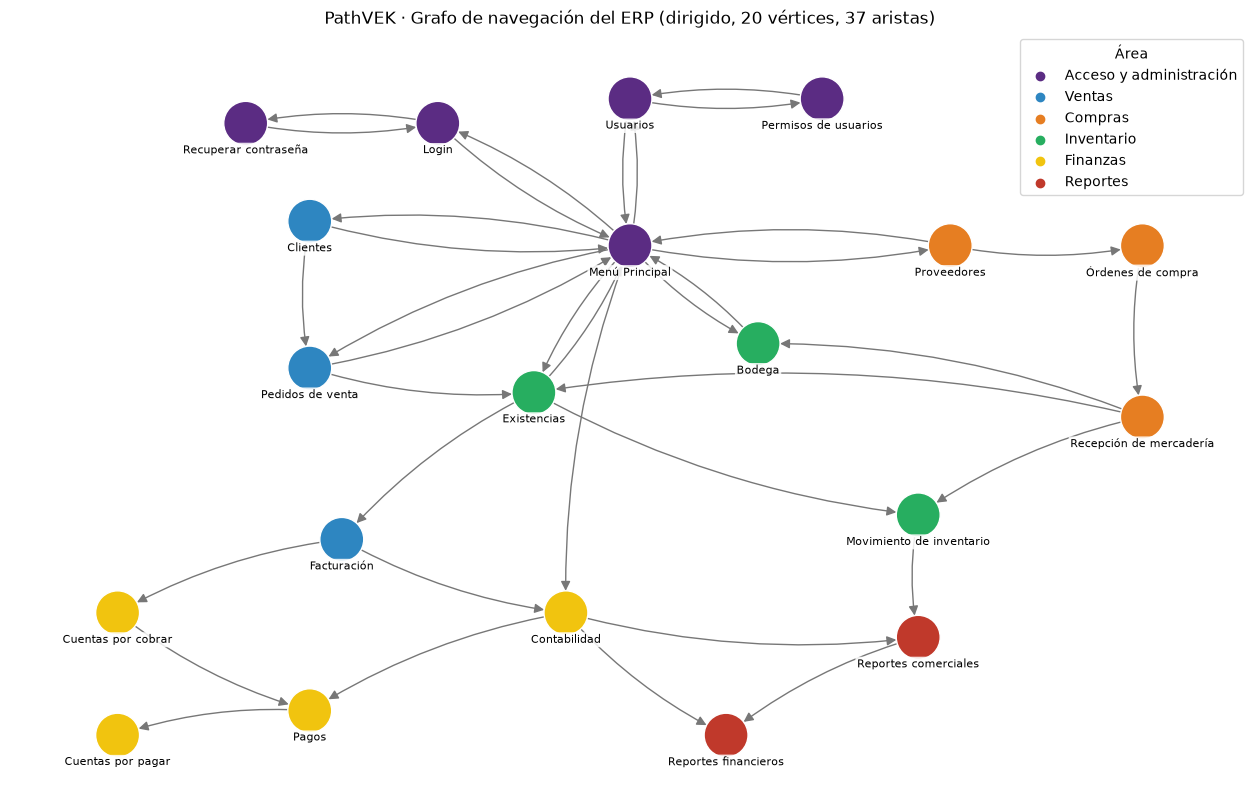

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

areas = {
    "Acceso y administración": ["Login", "Recuperar contraseña", "Menú Principal", "Usuarios", "Permisos de usuarios"],
    "Ventas": ["Clientes", "Pedidos de venta", "Facturación"],
    "Compras": ["Proveedores", "Órdenes de compra", "Recepción de mercadería"],
    "Inventario": ["Existencias", "Movimiento de inventario", "Bodega"],
    "Finanzas": ["Contabilidad", "Cuentas por cobrar", "Cuentas por pagar", "Pagos"],
    "Reportes": ["Reportes comerciales", "Reportes financieros"],
}
colores = {"Acceso y administración": "#5B2C83", "Ventas": "#2E86C1", "Compras": "#E67E22",
           "Inventario": "#27AE60", "Finanzas": "#F1C40F", "Reportes": "#C0392B"}
color_de = {n: colores[a] for a, nodos in areas.items() for n in nodos}

pos = {  # posiciones fijas: el dibujo es legible y siempre igual
    "Menú Principal": (0, 0), "Login": (-3, 2.5), "Recuperar contraseña": (-6, 2.5),
    "Usuarios": (0, 3), "Permisos de usuarios": (3, 3),
    "Clientes": (-5, 0.5), "Pedidos de venta": (-5, -2.5), "Existencias": (-1.5, -3),
    "Bodega": (2, -2), "Proveedores": (5, 0), "Órdenes de compra": (8, 0),
    "Recepción de mercadería": (8, -3.5), "Movimiento de inventario": (4.5, -5.5),
    "Facturación": (-4.5, -6), "Contabilidad": (-1, -7.5), "Cuentas por cobrar": (-8, -7.5),
    "Pagos": (-5, -9.5), "Cuentas por pagar": (-8, -10), "Reportes comerciales": (4.5, -8),
    "Reportes financieros": (1.5, -10),
}

G = nx.DiGraph(aristas)
plt.figure(figsize=(16, 10))
nx.draw_networkx_nodes(G, pos, node_color=[color_de[n] for n in G], node_size=1000, edgecolors="white")
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=14, node_size=1000,
                       connectionstyle="arc3,rad=0.1", edge_color="#777777")
nx.draw_networkx_labels(G, {n: (x, y - 0.55) for n, (x, y) in pos.items()}, font_size=8,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
for area, c in colores.items():
    plt.scatter([], [], color=c, label=area)
plt.legend(loc="upper right", title="Área")
plt.title("PathVEK · Grafo de navegación del ERP (dirigido, 20 vértices, 37 aristas)")
plt.axis("off")
plt.show()

In [5]:
# Exportación para Gephi (File → Open)
G_gephi = nx.DiGraph()
for n in grafo:
    G_gephi.add_node(n, label=n, area=next(a for a, nodos in areas.items() if n in nodos))
G_gephi.add_edges_from(aristas)
nx.write_gexf(G_gephi, "PathVEK_ERP.gexf")
print("Archivo generado: PathVEK_ERP.gexf")

Archivo generado: PathVEK_ERP.gexf


---
## 4. BFS · ruta con menor número de aristas *(Erick)*

### Diseño
- **Estrategia:** BFS explora por niveles. Primero visita las pantallas a un clic del origen, luego las que están a dos clics, y así sucesivamente.
- **Cola:** para explorar por niveles hay que atender primero lo que entró primero (FIFO). Por eso BFS usa una **cola**.
- **Ruta mínima:** como agota todos los caminos de longitud *k* antes de pasar a los de longitud *k + 1*, la primera vez que llega al destino lo hace con el menor número de aristas (grafo no ponderado).
- **Visitados:** cada pantalla se marca al encolarla. Evita repetir pantallas y que los ciclos (por ejemplo `Login ⇄ Recuperar contraseña`) generen un recorrido infinito.
- **Reconstrucción de la ruta:** para cada pantalla se guarda desde cuál se llegó (predecesor); al alcanzar el destino se recorre esa cadena hacia atrás.
- **Costo:** O(V + E), con V vértices y E aristas.

### Especificación
`bfs_camino_mas_corto(grafo, origen, destino)` devuelve la tupla `(ruta, distancia, orden)`:
- `ruta`: lista de pantallas de origen a destino, o `None` si no existe ruta.
- `distancia`: número de aristas de la ruta (0 si origen = destino), o `None` si no existe ruta.
- `orden`: lista de pantallas en el orden en que BFS las visitó.
- Si `origen` o `destino` no son vértices del grafo, lanza `ValueError`.

In [6]:
from collections import deque


def validar_pantallas(grafo, *pantallas):
    for p in pantallas:
        if p not in grafo:
            raise ValueError(f"La pantalla '{p}' no existe en el grafo")


def bfs_camino_mas_corto(grafo, origen, destino):
    validar_pantallas(grafo, origen, destino)

    predecesor = {origen: None}   # además de guardar el camino, marca las pantallas visitadas
    cola = deque([origen])
    orden = []

    while cola:
        actual = cola.popleft()
        orden.append(actual)

        if actual == destino:
            ruta = []
            while actual is not None:
                ruta.append(actual)
                actual = predecesor[actual]
            ruta.reverse()
            return ruta, len(ruta) - 1, orden

        for vecino in grafo[actual]:
            if vecino not in predecesor:
                predecesor[vecino] = actual
                cola.append(vecino)

    return None, None, orden

### Consulta C1: ruta con menos pasos de `Menú Principal` a `Reportes financieros`

In [7]:
ruta, distancia, orden = bfs_camino_mas_corto(grafo, "Menú Principal", "Reportes financieros")

print("Ruta     :", " → ".join(ruta))
print("Distancia:", distancia, "aristas")
print("Orden de exploración:", orden)

Ruta     : Menú Principal → Contabilidad → Reportes financieros
Distancia: 2 aristas
Orden de exploración: ['Menú Principal', 'Login', 'Clientes', 'Usuarios', 'Pedidos de venta', 'Proveedores', 'Existencias', 'Bodega', 'Contabilidad', 'Recuperar contraseña', 'Permisos de usuarios', 'Órdenes de compra', 'Facturación', 'Movimiento de inventario', 'Reportes comerciales', 'Reportes financieros']


---
## 5. DFS · alcanzabilidad y exploración *(Karen)*

### Diseño
- **Estrategia:** DFS sigue cada rama hasta el fondo antes de retroceder y probar otra.
- **Pila:** para volver a la última pantalla con ramas sin explorar se usa una **pila** (LIFO) o, de forma equivalente, la recursión. Aquí se usa una pila explícita.
- **Visitados:** evita volver a explorar pantallas y que los ciclos produzcan un recorrido infinito.
- **Orden de recorrido:** depende del orden en que se listan los vecinos en el diccionario. Los vecinos se apilan en orden inverso para que se visite primero el primero de la lista.
- **¿Por qué no garantiza la ruta con menos aristas?** DFS toma la primera rama disponible, no la más corta. Con los vecinos en el orden del diccionario, un DFS que parte de `Menú Principal` llega a `Facturación` recorriendo `Menú Principal → Clientes → Pedidos de venta → Existencias → Facturación` (4 aristas), mientras que BFS la alcanza en 2 aristas por `Existencias`.
- **Utilidad para el cliente:** responde qué pantallas son alcanzables desde un punto de partida y cuáles no.
- **Costo:** O(V + E).

### Especificación
`dfs_alcanzables(grafo, origen)` devuelve la tupla `(orden, no_alcanzables)`:
- `orden`: lista de pantallas alcanzables desde `origen` (incluido) en el orden en que DFS las visitó.
- `no_alcanzables`: lista de pantallas del grafo que no se pueden alcanzar desde `origen`.
- Si `origen` no es un vértice del grafo, lanza `ValueError`.

In [8]:
def dfs_alcanzables(grafo, origen):
    validar_pantallas(grafo, origen)

    visitados = set()
    orden = []
    pila = [origen]

    while pila:
        actual = pila.pop()
        if actual in visitados:
            continue
        visitados.add(actual)
        orden.append(actual)

        for vecino in reversed(grafo[actual]):
            if vecino not in visitados:
                pila.append(vecino)

    no_alcanzables = [p for p in grafo if p not in visitados]
    return orden, no_alcanzables

### Consulta C2: pantallas alcanzables desde `Facturación`

In [9]:
orden, no_alcanzables = dfs_alcanzables(grafo, "Facturación")

print(f"Alcanzables ({len(orden)}):", orden)
print(f"No alcanzables ({len(no_alcanzables)}):", no_alcanzables)

Alcanzables (7): ['Facturación', 'Contabilidad', 'Reportes comerciales', 'Reportes financieros', 'Pagos', 'Cuentas por pagar', 'Cuentas por cobrar']
No alcanzables (13): ['Login', 'Recuperar contraseña', 'Menú Principal', 'Usuarios', 'Permisos de usuarios', 'Clientes', 'Pedidos de venta', 'Proveedores', 'Órdenes de compra', 'Recepción de mercadería', 'Existencias', 'Movimiento de inventario', 'Bodega']


---
## 6. Casos de prueba

Pruebas mínimas del proyecto más la verificación de la consulta C2. Cada resultado esperado se derivó a mano sobre el
grafo de la sección 2.

| # | Prueba | Entrada | Resultado esperado |
|---|---|---|---|
| 1 | origen = destino | `Menú Principal → Menú Principal` | ruta `[Menú Principal]`, distancia 0 |
| 2 | existe una ruta | `Menú Principal → Reportes financieros` | `Menú Principal → Contabilidad → Reportes financieros`, distancia 2 |
| 3 | no existe una ruta | `Facturación → Menú Principal` | sin ruta (`None`) |
| 4 | dos o más rutas | `Menú Principal → Facturación` | BFS: distancia 2 por `Existencias`; existe otra ruta válida de 3 aristas por `Pedidos de venta` |
| 5 | el grafo contiene un ciclo | recorridos desde `Login` (ciclo `Login ⇄ Recuperar contraseña`) | terminan, sin pantallas repetidas |
| 6 | nodo inexistente | origen o destino `Módulo fantasma` | `ValueError` |
| 7 | un cambio estructural modifica la alcanzabilidad | agregar `Contabilidad → Menú Principal` y repetir la prueba 3 | antes: sin ruta; después: `Facturación → Contabilidad → Menú Principal`, distancia 2 |
| 8 | consulta C2 | DFS desde `Facturación` | 7 alcanzables y 13 no alcanzables |

In [10]:
import copy

MENU, FACT, RF = "Menú Principal", "Facturación", "Reportes financieros"


def verificar(nombre, condicion):
    print(f"[{'PASA' if condicion else 'FALLA'}] {nombre}")


def lanza_value_error(funcion, *args):
    try:
        funcion(*args)
    except ValueError:
        return True
    return False


def es_ruta_valida(grafo, ruta):
    return all(b in grafo[a] for a, b in zip(ruta, ruta[1:]))


# 1. origen = destino
ruta, dist, _ = bfs_camino_mas_corto(grafo, MENU, MENU)
verificar("1. origen = destino", ruta == [MENU] and dist == 0)

# 2. existe una ruta
ruta, dist, _ = bfs_camino_mas_corto(grafo, MENU, RF)
verificar("2. existe una ruta", ruta == [MENU, "Contabilidad", RF] and dist == 2)

# 3. no existe una ruta
ruta, dist, _ = bfs_camino_mas_corto(grafo, FACT, MENU)
verificar("3. no existe una ruta", ruta is None and dist is None)

# 4. dos o más rutas entre el mismo par
ruta, dist, _ = bfs_camino_mas_corto(grafo, MENU, FACT)
verificar("4a. BFS elige la ruta de 2 aristas", ruta == [MENU, "Existencias", FACT] and dist == 2)
ruta_alterna = [MENU, "Pedidos de venta", "Existencias", FACT]
verificar("4b. existe otra ruta válida y más larga", es_ruta_valida(grafo, ruta_alterna))

# 5. ciclo
orden, _ = dfs_alcanzables(grafo, "Login")
verificar("5a. DFS termina y no repite pantallas", len(orden) == len(set(orden)) and "Recuperar contraseña" in orden)
_, dist, _ = bfs_camino_mas_corto(grafo, "Login", "Recuperar contraseña")
verificar("5b. BFS termina con un ciclo", dist == 1)

# 6. nodo inexistente
verificar("6a. BFS: destino inexistente", lanza_value_error(bfs_camino_mas_corto, grafo, MENU, "Módulo fantasma"))
verificar("6b. BFS: origen inexistente", lanza_value_error(bfs_camino_mas_corto, grafo, "Módulo fantasma", MENU))
verificar("6c. DFS: origen inexistente", lanza_value_error(dfs_alcanzables, grafo, "Módulo fantasma"))

# 7. cambio estructural: agregar Contabilidad → Menú Principal
grafo_modificado = copy.deepcopy(grafo)
grafo_modificado["Contabilidad"].append(MENU)
ruta, dist, _ = bfs_camino_mas_corto(grafo_modificado, FACT, MENU)
verificar("7. tras agregar Contabilidad → Menú Principal hay ruta de 2 aristas",
          ruta == [FACT, "Contabilidad", MENU] and dist == 2)

# 8. consulta C2
alcanzables, no_alcanzables = dfs_alcanzables(grafo, FACT)
verificar("8. C2: 7 alcanzables y 13 no alcanzables desde Facturación",
          len(alcanzables) == 7 and len(no_alcanzables) == 13)

[PASA] 1. origen = destino
[PASA] 2. existe una ruta
[PASA] 3. no existe una ruta
[PASA] 4a. BFS elige la ruta de 2 aristas
[PASA] 4b. existe otra ruta válida y más larga
[PASA] 5a. DFS termina y no repite pantallas
[PASA] 5b. BFS termina con un ciclo
[PASA] 6a. BFS: destino inexistente
[PASA] 6b. BFS: origen inexistente
[PASA] 6c. DFS: origen inexistente
[PASA] 7. tras agregar Contabilidad → Menú Principal hay ruta de 2 aristas
[PASA] 8. C2: 7 alcanzables y 13 no alcanzables desde Facturación


---
## 7. Comparación BFS vs DFS

La comparación usa el mismo origen y destino en nuestro grafo: **`Menú Principal → Facturación`**.

| Criterio | BFS | DFS |
|---|---|---|
| Estructura auxiliar | Cola | Pila o recursión |
| Estrategia | Por niveles: primero los vecinos directos, luego los de segundo nivel | En profundidad: sigue una rama hasta el fondo antes de retroceder |
| ¿Ruta con menos aristas? | Sí, en grafo no ponderado | No necesariamente |
| Orden de visita | Resultado de la celda siguiente | Resultado de la celda siguiente |
| Resultado obtenido | Ruta de 2 aristas: `Menú Principal → Existencias → Facturación` | Llega a `Facturación` tras recorrer `Clientes → Pedidos de venta → Existencias`, una rama de 4 aristas |
| Uso para el cliente | Responde C1: cuántos pasos necesita un usuario para llegar a una pantalla | Responde C2: qué pantallas son alcanzables desde un punto y cuáles no |

In [11]:
ruta, distancia, orden_bfs = bfs_camino_mas_corto(grafo, "Menú Principal", "Facturación")
orden_dfs, _ = dfs_alcanzables(grafo, "Menú Principal")

print("BFS · ruta  :", " → ".join(ruta), f"({distancia} aristas)")
print("BFS · orden :", orden_bfs)
print("DFS · orden :", orden_dfs)

BFS · ruta  : Menú Principal → Existencias → Facturación (2 aristas)
BFS · orden : ['Menú Principal', 'Login', 'Clientes', 'Usuarios', 'Pedidos de venta', 'Proveedores', 'Existencias', 'Bodega', 'Contabilidad', 'Recuperar contraseña', 'Permisos de usuarios', 'Órdenes de compra', 'Facturación']
DFS · orden : ['Menú Principal', 'Login', 'Recuperar contraseña', 'Clientes', 'Pedidos de venta', 'Existencias', 'Facturación', 'Contabilidad', 'Reportes comerciales', 'Reportes financieros', 'Pagos', 'Cuentas por pagar', 'Cuentas por cobrar', 'Movimiento de inventario', 'Usuarios', 'Permisos de usuarios', 'Proveedores', 'Órdenes de compra', 'Recepción de mercadería', 'Bodega']


### Análisis
- **BFS** responde con certeza cuántos pasos necesita un usuario: `Menú Principal` llega a `Facturación` en 2 aristas, y su exploración por niveles garantiza que no existe una ruta más corta.
- **DFS** no mide distancias: informa qué pantallas se alcanzan y en qué orden se exploran. Su recorrido avanza por `Clientes → Pedidos de venta → Existencias → Facturación`, una rama de 4 aristas, antes de probar otras; por eso no sirve para afirmar cuál es la ruta más corta.
- **Elección según la pregunta del cliente:** para saber *cuál es la ruta con menos pasos* (C1) se usa BFS; para saber *qué se puede alcanzar y qué no* (C2) basta DFS.

---
## 8. Experimento estructural

Se modifica **una sola conexión**: se agrega `Contabilidad → Menú Principal`.

| Elemento | Contenido |
|---|---|
| **Estado inicial** | Desde `Facturación` no existe ruta a `Menú Principal`. DFS desde `Facturación` alcanza 7 pantallas (`Facturación`, `Contabilidad`, `Cuentas por cobrar`, `Pagos`, `Cuentas por pagar`, `Reportes comerciales`, `Reportes financieros`) y deja 13 sin alcanzar. |
| **Cambio** | Agregar la arista `Contabilidad → Menú Principal`, un botón de volver al menú en el módulo financiero. Tiene sentido en el dominio: es una opción común en cualquier módulo de un ERP. |
| **Resultado posterior** | Ruta `Facturación → Contabilidad → Menú Principal` (2 aristas). Desde `Facturación` pasan a alcanzarse las 20 pantallas y no queda ninguna inalcanzable. |
| **Interpretación** | Una sola arista convierte al flujo financiero, que era una zona sin salida, en parte del recorrido normal del sistema: desde `Contabilidad` se vuelve al menú y desde él se llega al resto de módulos. |
| **Recomendación al cliente** | Agregar el botón de volver al menú en `Contabilidad` (ver sección 10). |

In [12]:
antes_ruta, _, _ = bfs_camino_mas_corto(grafo, FACT, MENU)
antes_alcanzables, antes_no = dfs_alcanzables(grafo, FACT)

despues_ruta, despues_dist, _ = bfs_camino_mas_corto(grafo_modificado, FACT, MENU)
despues_alcanzables, despues_no = dfs_alcanzables(grafo_modificado, FACT)

print("ANTES   · ruta a Menú Principal:", antes_ruta)
print("ANTES   · alcanzables:", len(antes_alcanzables), "| no alcanzables:", len(antes_no))
print("DESPUÉS · ruta a Menú Principal:", " → ".join(despues_ruta), f"({despues_dist} aristas)")
print("DESPUÉS · alcanzables:", len(despues_alcanzables), "| no alcanzables:", len(despues_no))

ANTES   · ruta a Menú Principal: None
ANTES   · alcanzables: 7 | no alcanzables: 13
DESPUÉS · ruta a Menú Principal: Facturación → Contabilidad → Menú Principal (2 aristas)
DESPUÉS · alcanzables: 20 | no alcanzables: 0


---
## 9. AI-Audit

Auditoría crítica de una solución generada por IA. **Los campos entre corchetes los completa el equipo con su
conversación real** (prompt y enlace); el análisis técnico de la propuesta ya está documentado.

**Caso:** diccionario inicial del grafo (si fue generado con IA). Tenía 20 pantallas, pero cada conexión tenía su retorno.

| Punto | Contenido |
|---|---|
| 1. Prompt y enlace de la conversación | `[COMPLETAR: prompt y enlace]` |
| 2. Solución propuesta por la IA | Diccionario `grafo_erp` con 20 vértices en el que toda arista tenía su arista inversa, descrito como grafo dirigido. |
| 3. Qué hace realmente | Cuenta 56 aristas dirigidas (28 pares de ida y vuelta). Como todas las conexiones son recíprocas, se comporta como un grafo **no dirigido**. |
| 4. Prueba o contraejemplo del equipo | (a) 56 aristas superan el máximo de 40 del proyecto. (b) Con toda arista recíproca, desde cualquier pantalla se llega a todas: no existe ningún par sin ruta, por lo que la prueba "no existe una ruta" y las pantallas no alcanzables no se podían demostrar. |
| 5. Veredicto | Parcialmente correcta: nodos y nombres válidos, pero el modelo incumple el límite de aristas y contradice la decisión de grafo dirigido. |
| 6. Corrección | Se dejaron de ida y vuelta solo el acceso y el menú (9 pares) y el resto en un sentido, hasta 37 aristas dirigidas. Aparecen pantallas no alcanzables (13 desde `Facturación`). |
| 7. Verificación | Validación de cantidades en la sección 3 y pruebas 3, 7 y 8 de la sección 6. |

---
## 10. Recomendaciones al cliente
1. **Agregar un botón de volver al menú en `Contabilidad`.** Con una sola conexión (`Contabilidad → Menú Principal`), el flujo financiero deja de ser una zona sin salida: desde `Facturación` pasan a alcanzarse todas las pantallas.
2. **Dar salida a las pantallas sin conexiones de salida.** `Cuentas por pagar` y `Reportes financieros` no llevan a ninguna otra pantalla; conviene enlazarlas de regreso a `Contabilidad` o al menú.
3. **Mantener los accesos actuales a los destinos más usados.** `Reportes financieros` se alcanza en 2 pasos desde el menú y `Facturación` también, por lo que no se requieren atajos adicionales.
4. **Alcance de las recomendaciones.** Se basan en la estructura de navegación modelada; no evalúan rendimiento, seguridad ni uso real del ERP.

---
## 11. Conclusiones
- El ERP hipotético se modeló como un grafo dirigido y no ponderado de **20 pantallas y 37 conexiones**, que cumple los requisitos del proyecto.
- **BFS** permitió responder C1: la ruta con menos pasos de `Menú Principal` a `Reportes financieros` tiene 2 aristas.
- **DFS** permitió responder C2: desde `Facturación` se alcanzan 7 pantallas y 13 quedan fuera de alcance, entre ellas `Menú Principal`.
- La comparación mostró que BFS sirve para medir pasos y DFS para estudiar alcanzabilidad; DFS no garantiza la ruta más corta.
- El experimento (C3) mostró que una sola arista, `Contabilidad → Menú Principal`, elimina las pantallas inalcanzables desde `Facturación`.
- **Limitaciones:** el modelo es hipotético y analiza solo la estructura de navegación, sin pesos ni perfiles de permisos.

---
## 12. Declaración de uso de IA
| Herramienta | Finalidad | Nivel de uso | Prompt / enlace | Cómo se verificó |
|---|---|---|---|---|
| ChatGPT | Planteamiento inicial del escenario ERP y borrador del problema del cliente | AI-Tutor | `[COMPLETAR enlace]` | Se contrastó con el documento del proyecto y se corrigieron errores de redacción y de nombres. |
| Claude | Revisión de requisitos y rúbrica, definición del modelo del grafo, redacción de las secciones de modelado y estructura del notebook, y código base de BFS (sección 4) y DFS (sección 5) | AI-Copilot | `[COMPLETAR enlace]` | Cantidades validadas con la celda de la sección 3; BFS y DFS probados con la sección 6. `[COMPLETAR: qué trazó y revisó el equipo a mano]` |
| NetworkX / Matplotlib / Gephi | Solo visualización del grafo; no ejecutan BFS ni DFS | Visualización | n/a | El dibujo coincide con el diccionario de la sección 3. |

---
## 13. Referencias
- Cormen, T. H., Leiserson, C. E., Rivest, R. L. y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.). MIT Press.
- Hagberg, A. A., Schult, D. A. y Swart, P. J. (2008). Exploring network structure, dynamics, and function using NetworkX. *Proceedings of the 7th Python in Science Conference (SciPy 2008)*.
- Bastian, M., Heymann, S. y Jacomy, M. (2009). Gephi: an open source software for exploring and manipulating networks. *International AAAI Conference on Weblogs and Social Media*.
- Python Software Foundation. Documentación de Python: módulo `collections` (`deque`).

---
## 14. Registro de contribuciones
| Integrante | Rol | Aporte | Evidencia |
|---|---|---|---|
| Grefa Huatatoca Karen Mishelle | Product & SI Analyst | Problema del cliente, modelado y visualización del grafo, DFS, pruebas y comparación | Secciones 5, 6 y 7 |
| Guachagmira Anrango Erick Said | Algorithm Engineer | Representación en Python y BFS | Secciones 3 y 4 |
| Guzman Pillajo Vianca Alejandra | QA & Insights Engineer | Experimento estructural y AI-Audit | Secciones 8 y 9 |

### Checklist de entrega
- [ ] Reiniciar el kernel y ejecutar todas las celdas sin errores.
- [ ] Trazar BFS y DFS a mano sobre el grafo y poder explicar cada línea del código.
- [ ] Comprobar que las pruebas de la sección 6 dicen `PASA`.
- [ ] Completar prompt y enlace de la sección 9 y los enlaces de la sección 12.
- [ ] Todos pueden explicar cualquier parte esencial del proyecto.